# Day 3 lecture: Forecasting

<p class="lead">
Budgets, stock orders, staff rosters and climate policy all rest on a forecast. This lecture shows how to read a time series as trend, seasonality and noise, how to forecast it with moving averages, exponential smoothing and ARIMA models, how to test a forecast honestly on data the model has never seen, and how to report the uncertainty with a forecast interval.
</p>

Open this notebook in JupyterLab from the course folder and run each cell from top to bottom with **Shift + Enter**.

---

## What you will be able to do

1. Describe a time series by its **trend**, **seasonality** and **noise**, and split it with a **decomposition**.
2. Smooth a series with a **moving average** and explain why a trailing average lags behind a trend.
3. Split a time series into **training** and **test** periods in time order, and explain why it must not be shuffled.
4. Compute and interpret **MAE**, **RMSE** and **MAPE**, and compare models with a **baseline**.
5. Explain **exponential smoothing** (simple, Holt and Holt-Winters) as a weighted average that forgets the past.
6. Explain the idea of **ARIMA**: autoregression, differencing to remove trend (**stationarity**), and moving-average errors; read an **ADF test**.
7. Produce a **forecast interval**, explain why it widens with the horizon, and state a forecast for a decision-maker.

**Reading:** TransImpact (n.d.), *Forecasting methods: The complete guide*.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words, alone or with the person next to you.

| Part | Topic |
|---|---|
| 1 | Why forecast, and the words we use |
| 2 | The data: CO₂ at Mauna Loa |
| 3 | Trend, seasonality and decomposition |
| 4 | Moving averages |
| 5 | Train and test in time order |
| 6 | Measuring forecast error, and baselines |
| 7 | Exponential smoothing |
| 8 | The ARIMA idea |
| 9 | Forecast intervals |
| 10 | Choosing a model and making the decision |

---

## Part 1: Why forecast, and the words we use

A **forecast** is an estimate of a future value, made from past data and stated with its uncertainty. It is **predictive** analytics: it answers *what is likely to happen?* The decision about what to do with it is **prescriptive**.

| Decision | Series to forecast | Horizon |
|---|---|---|
| How much milk tea powder to order next month | Monthly drinks sold | 1 month |
| How many call-centre staff to roster next week | Calls per hour | 1–2 weeks |
| Next year's budget | Monthly revenue | 12 months |
| Emission targets | Atmospheric CO₂ | Years |

| Word | Meaning |
|---|---|
| **Time series** | Values of one measure recorded at regular intervals, in time order |
| **Horizon** | How far ahead we forecast (1 month, 12 months, …) |
| **Point forecast** | The single most likely value |
| **Forecast interval** | A range expected to contain the future value with a stated probability, for example 95% |
| **Holdout** or **test period** | Recent data hidden from the model, used to measure its error |

The setup cell loads the libraries. Every model in this lecture comes from `statsmodels`, part of Anaconda.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

# Recent statsmodels versions print a notice that adfuller's output format will change
# in a future release. It does not change any result, so we hide that notice.
warnings.filterwarnings("ignore", category=FutureWarning)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"   # context
INK = "#55534e"    # notes and labels
plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

---

## Part 2: The data: CO₂ at Mauna Loa

The Mauna Loa Observatory in Hawaii has measured carbon dioxide (CO₂) in the air since 1958. The measure is the **concentration in parts per million (ppm)**: how many CO₂ molecules there are in every million molecules of air. The series ships inside `statsmodels`, so it loads without internet. It is weekly, with some weeks missing; we average it to **monthly** values, and fill the few months with no measurement by carrying the previous month forward.

In [2]:
weekly = sm.datasets.co2.load_pandas().data
monthly_raw = weekly["co2"].resample("ME").mean()   # "ME" = month end
co2 = monthly_raw.ffill()

print("Weekly rows:", len(weekly), "| weeks with no value:", weekly["co2"].isna().sum())
print("Monthly values:", len(co2), "from", co2.index[0].strftime("%b %Y"), "to", co2.index[-1].strftime("%b %Y"))
print("Months with no measurement, filled from the month before:", monthly_raw.isna().sum())
co2.head()

Weekly rows: 2284 | weeks with no value: 59
Monthly values: 526 from Mar 1958 to Dec 2001
Months with no measurement, filled from the month before: 5


1958-03-31    316.100000
1958-04-30    317.200000
1958-05-31    317.433333
1958-06-30    317.433333
1958-07-31    315.625000
Freq: ME, Name: co2, dtype: float64

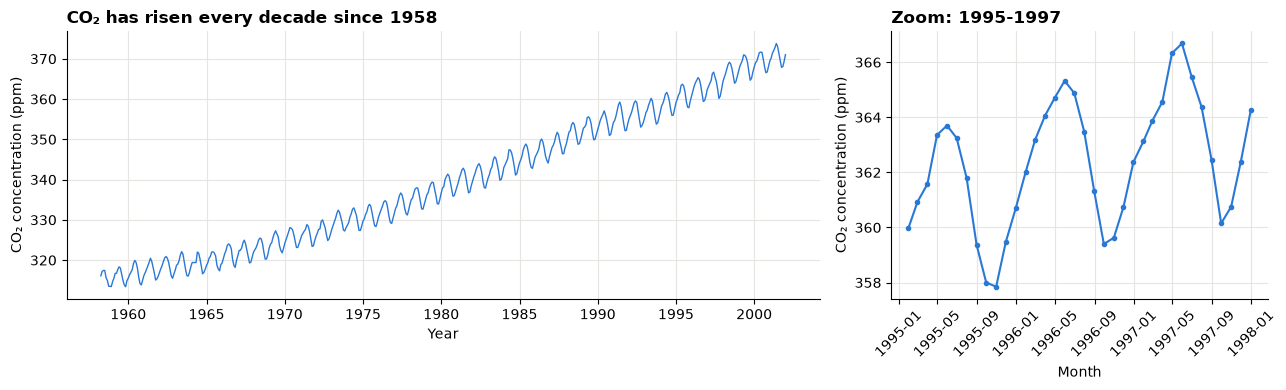

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})
ax1.plot(co2.index, co2, color=BLUE, linewidth=1)
ax1.set_title("CO₂ has risen every decade since 1958")
ax1.set_xlabel("Year")
ax1.set_ylabel("CO₂ concentration (ppm)")

recent = co2["1995":"1997"]
ax2.plot(recent.index, recent, color=BLUE, marker="o", markersize=3)
ax2.set_title("Zoom: 1995-1997")
ax2.set_xlabel("Month")
ax2.set_ylabel("CO₂ concentration (ppm)")
ax2.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

> **Predict, then reveal**
>
> Look at the zoomed panel above. In which **month** of the year is CO₂ highest, and in which is it lowest? (Hint: think about when the forests of the Northern Hemisphere grow leaves.) We check your answer in Part 3.

---

## Part 3: Trend, seasonality and decomposition

Most business and natural time series are a mix of a few **components**:

| Component | Meaning | CO₂ example | Business example |
|---|---|---|---|
| **Trend** | The long-run direction | Rising every year | Sales growing as a chain opens shops |
| **Seasonality** | A pattern that repeats with a fixed period | Peak in spring, dip in autumn, every 12 months | More drinks in summer; more calls on Mondays |
| **Cycle** | Longer swings without a fixed period | (small here) | Economic booms and recessions |
| **Noise** (residual) | What is left: irregular, unpredictable | Weather, measurement | One-off events, chance |

In an **additive** model, value = trend + seasonal + residual: the seasonal swing has the same size in ppm every year. In a **multiplicative** model, value = trend × seasonal × residual: the swing grows with the level, as with sales that rise 30% every December. The CO₂ swing stays about the same size, so we use additive.

`seasonal_decompose` estimates each component. The trend is a centred 12-month moving average (Part 4), the seasonal part is the average deviation from the trend for each calendar month, and the residual is the rest.

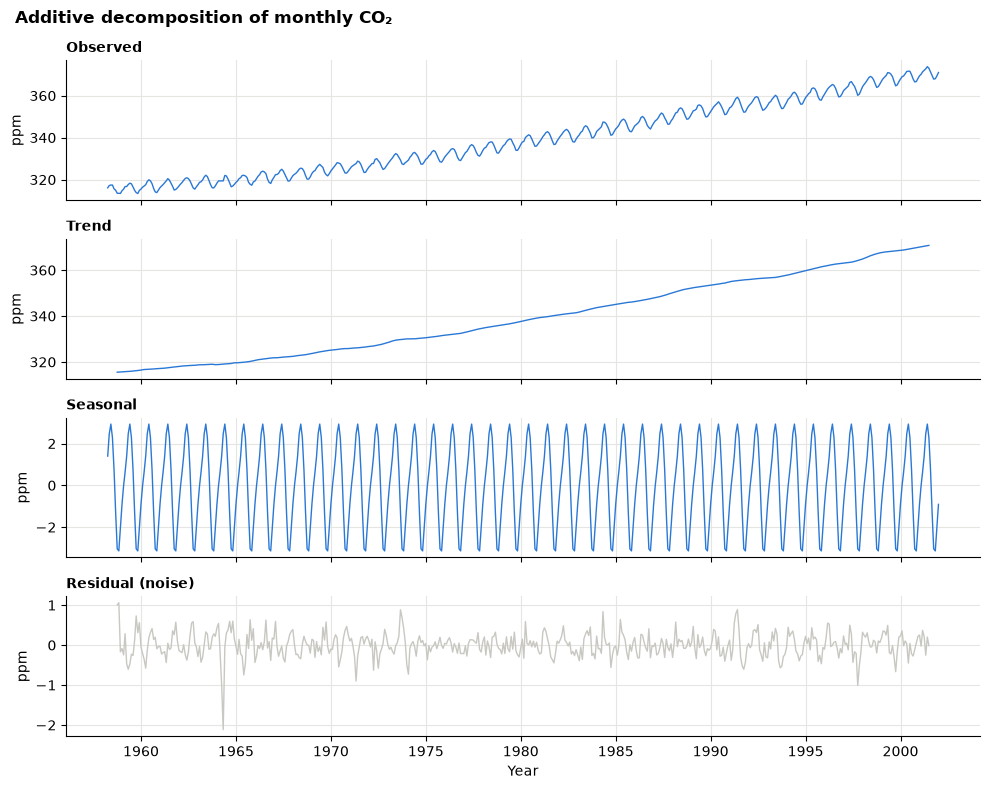

In [4]:
parts = seasonal_decompose(co2, model="additive", period=12)

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, series, title in zip(
    axes,
    [co2, parts.trend, parts.seasonal, parts.resid],
    ["Observed", "Trend", "Seasonal", "Residual (noise)"],
):
    ax.plot(series.index, series, color=BLUE if title != "Residual (noise)" else GREY, linewidth=1)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("ppm")
axes[-1].set_xlabel("Year")
fig.suptitle("Additive decomposition of monthly CO₂", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [5]:
seasonal_effect = parts.seasonal.groupby(parts.seasonal.index.month).mean()
seasonal_effect.index = pd.to_datetime(seasonal_effect.index, format="%m").strftime("%b")

print("Average seasonal effect by calendar month (ppm above or below the trend)")
print(seasonal_effect.round(2).to_string())
print(f"\nHighest month: {seasonal_effect.idxmax()} | lowest month: {seasonal_effect.idxmin()}")
print(f"Seasonal swing, highest minus lowest: {seasonal_effect.max() - seasonal_effect.min():.2f} ppm")

Average seasonal effect by calendar month (ppm above or below the trend)
Jan   -0.01
Feb    0.62
Mar    1.40
Apr    2.46
May    2.93
Jun    2.29
Jul    0.75
Aug   -1.31
Sep   -3.04
Oct   -3.14
Nov   -2.04
Dec   -0.91

Highest month: May | lowest month: Oct
Seasonal swing, highest minus lowest: 6.07 ppm


Check your prediction against the output above. Plants in the Northern Hemisphere absorb CO₂ as they grow in summer, so concentration falls from late spring to early autumn and rises again over winter.

> **Check your understanding**
>
> 1. A shop's monthly sales rise by about 2% a year and are 40% higher every December than in an average month. Name the components, and say whether you would use an additive or a multiplicative model.
> 2. Why are the first and last six months of the trend panel empty?

---

## Part 4: Moving averages

A **moving average** replaces each value with the average of a window of neighbouring values. It smooths out the noise and the seasonal swing so the trend is easier to see.

| Type | Window | Use |
|---|---|---|
| **Centred** | Months before *and* after | Describing the past (the trend line in a decomposition) |
| **Trailing** | The last *k* months only | Forecasting: it uses only what is already known |

A 12-month window contains exactly one of each calendar month, so the seasonal swing cancels out.

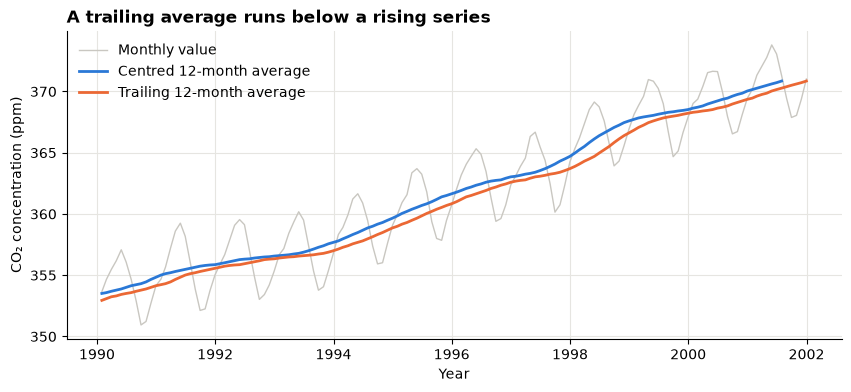

On average, the monthly value is 0.69 ppm above its trailing 12-month average (1990-2001).


In [6]:
window = co2["1990":]
centred = co2.rolling(12, center=True).mean()["1990":]
trailing = co2.rolling(12).mean()["1990":]

fig, ax = plt.subplots()
ax.plot(window.index, window, color=GREY, linewidth=1, label="Monthly value")
ax.plot(centred.index, centred, color=BLUE, linewidth=2, label="Centred 12-month average")
ax.plot(trailing.index, trailing, color=ORANGE, linewidth=2, label="Trailing 12-month average")
ax.set_title("A trailing average runs below a rising series")
ax.set_xlabel("Year")
ax.set_ylabel("CO₂ concentration (ppm)")
ax.legend(frameon=False)
plt.show()

gap = (window - trailing).mean()
print(f"On average, the monthly value is {gap:.2f} ppm above its trailing 12-month average (1990-2001).")

The trailing average describes the middle of the last twelve months, about six months ago. When the series has a trend, a forecast that says "next month = average of the last 12 months" will be **systematically too low** for a rising series (too high for a falling one). Forecasting methods that follow a trend fix this.

---

## Part 5: Train and test in time order

How do we know whether a forecast is good before the future arrives? We pretend part of the past is the future:

1. Hide the most recent months: the **test** period (also called holdout).
2. Fit the model on the earlier months only: the **training** period.
3. Forecast the test period and compare with what actually happened.

Here we hide the last **36 months** (1999–2001) and train on everything before.

> **Never shuffle a time series**
>
> In a random split, the model would train on months *after* some test months and "see the future". The test must come **after** the training data, exactly as in real forecasting.

Training: Mar 1958 to Dec 1998 (490 months)
Test:     Jan 1999 to Dec 2001 (36 months)


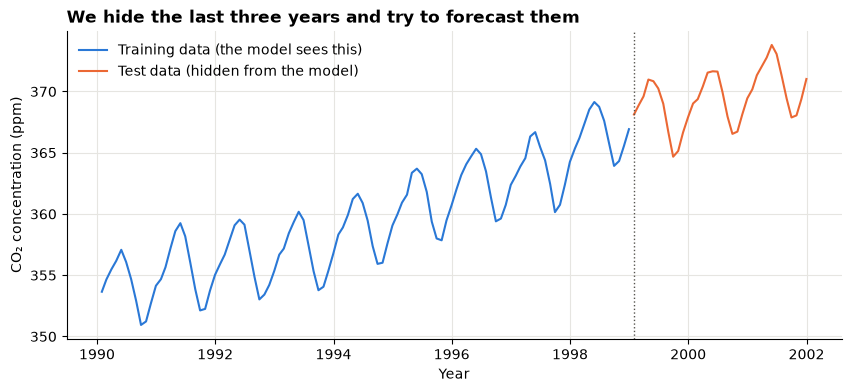

In [7]:
HORIZON = 36
train, test = co2.iloc[:-HORIZON], co2.iloc[-HORIZON:]

print(f"Training: {train.index[0]:%b %Y} to {train.index[-1]:%b %Y} ({len(train)} months)")
print(f"Test:     {test.index[0]:%b %Y} to {test.index[-1]:%b %Y} ({len(test)} months)")

fig, ax = plt.subplots()
ax.plot(train["1990":].index, train["1990":], color=BLUE, label="Training data (the model sees this)")
ax.plot(test.index, test, color=ORANGE, label="Test data (hidden from the model)")
ax.axvline(test.index[0], color=INK, linestyle=":", linewidth=1)
ax.set_title("We hide the last three years and try to forecast them")
ax.set_xlabel("Year")
ax.set_ylabel("CO₂ concentration (ppm)")
ax.legend(frameon=False, loc="upper left")
plt.show()

---

## Part 6: Measuring forecast error, and baselines

The **error** for one month is actual minus forecast. Three ways to summarise many errors:

| Measure | Formula, in words | Units | Read it as |
|---|---|---|---|
| **MAE**, mean absolute error | Average of the absolute errors | Same as the data (ppm) | "On average the forecast is off by … ppm" |
| **RMSE**, root mean squared error | Square the errors, average, take the square root | Same as the data | Like MAE, but punishes large misses more; always ≥ MAE |
| **MAPE**, mean absolute percentage error | Average of absolute error ÷ actual, in % | Per cent | "Off by …% on average"; easy to explain, but misleading when actual values are near zero |

Always compare a model with a **baseline**: a forecast so simple that a model must beat it to be worth using.

| Baseline | Forecast for every future month |
|---|---|
| **Naive** | The last value seen |
| **Seasonal naive** | The value in the same month one year earlier |
| **Average** | The average of the last 12 months (the trailing moving average) |

In [8]:
def forecast_errors(actual, forecast):
    """MAE, RMSE and MAPE of a forecast against the actual values."""
    error = np.asarray(actual) - np.asarray(forecast)
    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE %": 100 * np.mean(np.abs(error / np.asarray(actual))),
    }


forecasts = pd.DataFrame(index=test.index)
forecasts["naive"] = train.iloc[-1]
forecasts["seasonal naive"] = np.tile(train.iloc[-12:].values, HORIZON // 12)
forecasts["12-month average"] = train.iloc[-12:].mean()

scores = pd.DataFrame({name: forecast_errors(test, forecasts[name]) for name in forecasts}).T
scores.round(3)

,MAE,RMSE,MAPE %
naive,2.839,3.336,0.766
seasonal naive,2.866,3.109,0.774
12-month average,3.059,3.580,0.825


> **Predict, then reveal**
>
> All three baselines are flat or repeat last year. Before you run the next cell, sketch what each one looks like against the rising test data. Which one will at least follow the seasonal zig-zag?

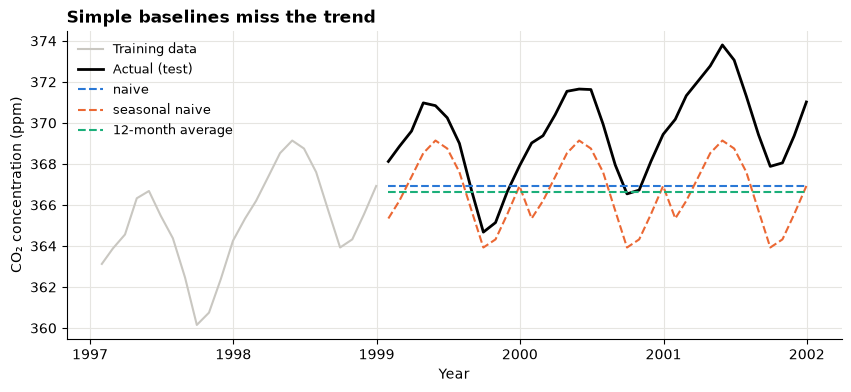

In [9]:
fig, ax = plt.subplots()
ax.plot(train["1997":].index, train["1997":], color=GREY, label="Training data")
ax.plot(test.index, test, color="black", linewidth=2, label="Actual (test)")
for name, colour in zip(forecasts.columns, [BLUE, ORANGE, AQUA]):
    ax.plot(forecasts.index, forecasts[name], color=colour, linestyle="--", label=name)
ax.set_title("Simple baselines miss the trend")
ax.set_xlabel("Year")
ax.set_ylabel("CO₂ concentration (ppm)")
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.show()

In the table above, MAPE is well under 1% for every baseline. That looks excellent, but only because the level of CO₂ is large. A fairer yardstick is the size of the **changes we care about**: the seasonal swing from Part 3 is a few ppm, and the trend adds well over 1 ppm a year. Judge an error against the decision, not only against the level.

> **Check your understanding**
>
> A forecast of daily sales has a MAPE of 4% on most days but 300% on public holidays, when the shop is almost closed. What causes the 300%, and which measure would you report instead?

---

## Part 7: Exponential smoothing

A moving average gives the last 12 months equal weight and everything older no weight. **Exponential smoothing** gives *every* past value a weight that shrinks the further back it is. One number, **α** (alpha, between 0 and 1), sets how quickly the past is forgotten.

In [10]:
weights = pd.DataFrame({
    f"alpha = {alpha}": [alpha * (1 - alpha) ** k for k in range(6)] for alpha in (0.2, 0.8)
}, index=["latest month", "1 month ago"] + [f"{k} months ago" for k in range(2, 6)])
print("Weight given to each past value")
weights.round(3)

Weight given to each past value


,alpha = 0.2,alpha = 0.8
latest month,0.200,0.800
1 month ago,0.160,0.160
2 months ago,0.128,0.032
3 months ago,0.102,0.006
4 months ago,0.082,0.001
5 months ago,0.066,0.000


With a large α, the forecast follows the latest values closely (reacts fast, but also to noise). With a small α, it averages over a long history (stable, but slow to react). The model chooses α by fitting the training data.

| Method | Follows | Use when the series has |
|---|---|---|
| **Simple exponential smoothing** | A level only | No trend, no seasonality |
| **Holt** (double) | Level + trend | A trend, no seasonality |
| **Holt-Winters** (triple) | Level + trend + seasonality | A trend and a repeating season |

In [11]:
ses = SimpleExpSmoothing(train, initialization_method="estimated").fit()
holt = ExponentialSmoothing(train, trend="add", initialization_method="estimated").fit()
holt_winters = ExponentialSmoothing(
    train, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated"
).fit()

forecasts["simple smoothing"] = ses.forecast(HORIZON).values
forecasts["Holt"] = holt.forecast(HORIZON).values
forecasts["Holt-Winters"] = holt_winters.forecast(HORIZON).values

print(f"Simple smoothing: alpha = {ses.params['smoothing_level']:.2f}")
print(f"Holt-Winters: alpha = {holt_winters.params['smoothing_level']:.2f}, "
      f"trend weight = {holt_winters.params['smoothing_trend']:.3f}, "
      f"seasonal weight = {holt_winters.params['smoothing_seasonal']:.2f}")

for name in ["simple smoothing", "Holt", "Holt-Winters"]:
    scores.loc[name] = forecast_errors(test, forecasts[name])
scores.round(3)

Simple smoothing: alpha = 1.00
Holt-Winters: alpha = 0.54, trend weight = 0.011, seasonal weight = 0.13


,MAE,RMSE,MAPE %
naive,2.839,3.336,0.766
seasonal naive,2.866,3.109,0.774
12-month average,3.059,3.580,0.825
simple smoothing,2.839,3.336,0.766
Holt,22.883,26.696,6.190
Holt-Winters,0.810,0.889,0.219


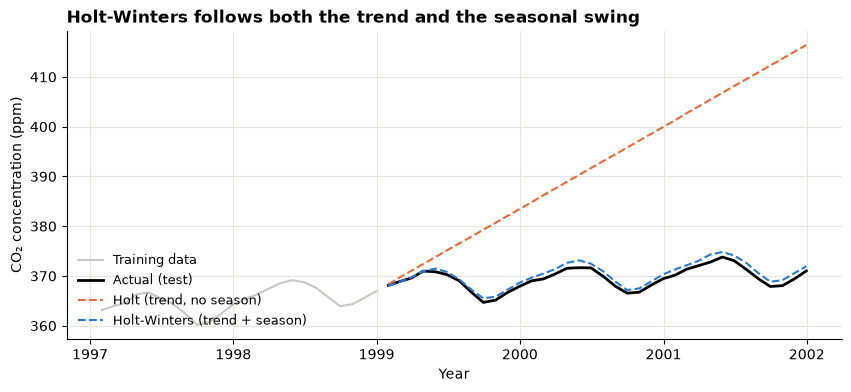

In [12]:
fig, ax = plt.subplots()
ax.plot(train["1997":].index, train["1997":], color=GREY, label="Training data")
ax.plot(test.index, test, color="black", linewidth=2, label="Actual (test)")
ax.plot(forecasts.index, forecasts["Holt"], color=ORANGE, linestyle="--", label="Holt (trend, no season)")
ax.plot(forecasts.index, forecasts["Holt-Winters"], color=BLUE, linestyle="--", label="Holt-Winters (trend + season)")
ax.set_title("Holt-Winters follows both the trend and the seasonal swing")
ax.set_xlabel("Year")
ax.set_ylabel("CO₂ concentration (ppm)")
ax.legend(frameon=False, loc="lower left", fontsize=9)
plt.show()

Read the chart and the error table above:

- **Simple smoothing** behaves like the naive forecast: it has no trend, so it is flat.
- **Holt** has a trend but no season. The training data end in December, in the middle of the yearly climb from the autumn low, when CO₂ rises by more than 1 ppm a month. Holt has no seasonal part, so it reads that seasonal climb as the long-run trend and carries it forward for three years: its forecast shoots far above the actual values. A model that ignores a real pattern can do **much worse than a baseline**.
- **Holt-Winters** models trend and season, and its errors are far smaller than the baselines'.

---

## Part 8: The ARIMA idea

**ARIMA** is the other big family of forecasting models. The name lists its three ingredients:

| Letter | Name | Idea in plain words | Order |
|---|---|---|---|
| **AR** | AutoRegressive | This month depends on the last few months' **values** | p |
| **I** | Integrated | Model the **changes** (differences) instead of the levels, to remove the trend | d |
| **MA** | Moving Average (of errors) | This month corrects for the last few months' **forecast errors** | q |

It is written ARIMA(p, d, q). **Seasonal ARIMA** (SARIMA) adds the same three ingredients at the seasonal lag, written (P, D, Q, s) with s = 12 for monthly data.

### Stationarity and differencing

ARIMA needs a **stationary** series: one whose average and spread do not drift over time. A trending series is not stationary. **Differencing** fixes this: instead of the CO₂ level, model the change from one month to the next (d = 1). A **seasonal difference** (D = 1) models the change from the same month last year.

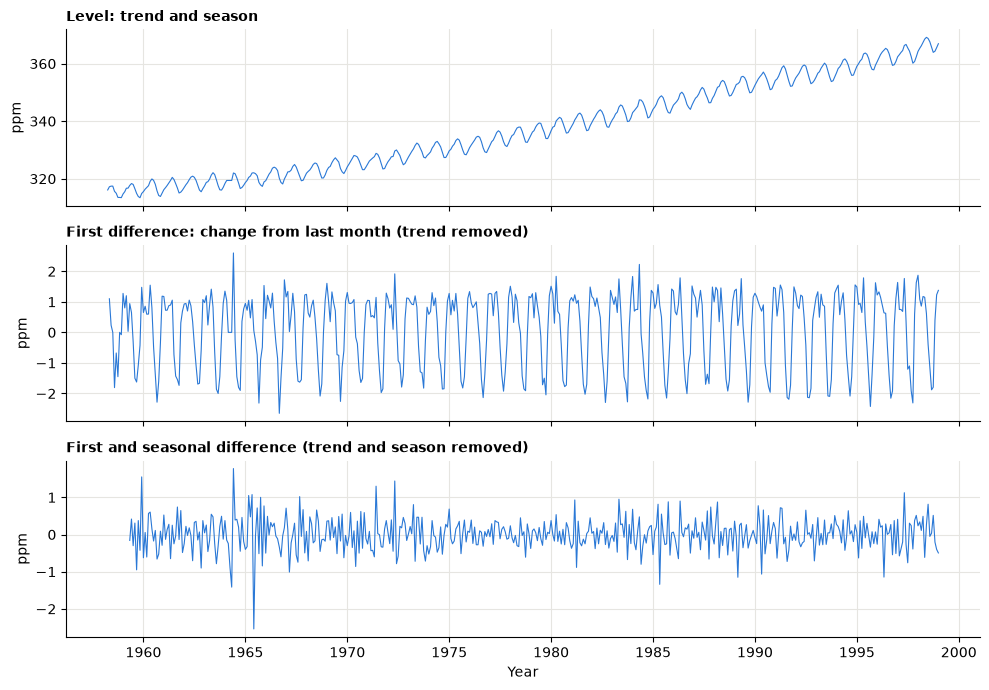

In [13]:
first_diff = train.diff()
both_diff = train.diff().diff(12)

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, series, title in zip(
    axes,
    [train, first_diff, both_diff],
    ["Level: trend and season", "First difference: change from last month (trend removed)",
     "First and seasonal difference (trend and season removed)"],
):
    ax.plot(series.index, series, color=BLUE, linewidth=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("ppm")
axes[-1].set_xlabel("Year")
fig.tight_layout()
plt.show()

The **Augmented Dickey-Fuller (ADF) test** checks stationarity with numbers instead of eyes:

| | |
|---|---|
| **Null hypothesis** | The series is **not** stationary (it has a "unit root", a wandering trend) |
| **p-value > 0.05** | Not enough evidence of stationarity: difference the series |
| **p-value ≤ 0.05** | Reject the null: treat the series as stationary |

We run it on the **training** data, as levels and after differencing:

In [14]:
for label, series in [("Level", train), ("First difference", first_diff),
                      ("First and seasonal difference", both_diff)]:
    statistic, p_value = adfuller(series.dropna())[:2]
    verdict = "stationary" if p_value <= 0.05 else "NOT stationary"
    print(f"{label:<31} ADF statistic = {statistic:8.3f}   p-value = {p_value:.4f}   -> {verdict}")

Level                           ADF statistic =    2.588   p-value = 0.9991   -> NOT stationary
First difference                ADF statistic =   -3.869   p-value = 0.0023   -> stationary
First and seasonal difference   ADF statistic =   -8.241   p-value = 0.0000   -> stationary


Read the p-values above: the level series is not stationary, and differencing makes it stationary. That is why the model below sets d = 1 (and D = 1 for the season).

We fit a classic seasonal ARIMA, SARIMA(0, 1, 1)(0, 1, 1, 12), often called the **airline model** because it was first used for monthly airline passengers. Software chooses the coefficients; your job is to choose a sensible structure, check the errors on the test period and explain the result.

In [15]:
sarima = sm.tsa.statespace.SARIMAX(train, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
sarima_forecast = sarima.get_forecast(steps=HORIZON)
forecasts["SARIMA"] = sarima_forecast.predicted_mean.values

scores.loc["SARIMA"] = forecast_errors(test, forecasts["SARIMA"])
scores.round(3)

,MAE,RMSE,MAPE %
naive,2.839,3.336,0.766
seasonal naive,2.866,3.109,0.774
12-month average,3.059,3.580,0.825
simple smoothing,2.839,3.336,0.766
Holt,22.883,26.696,6.190
Holt-Winters,0.810,0.889,0.219
SARIMA,1.007,1.098,0.272


> **Check your understanding**
>
> 1. A colleague fits ARIMA to monthly sales that grow every year, with d = 0. What problem do you expect, and what would an ADF test have told them?
> 2. In your own words: what does the "MA" in ARIMA average, and how is that different from a moving average of the values in Part 4?

---

## Part 9: Forecast intervals

A point forecast alone suggests more certainty than anyone has. A **95% forecast interval** is a range that should contain the actual value in about 95 of 100 similar forecasts. SARIMA gives intervals directly.

> **Predict, then reveal**
>
> Will the interval for the 36th month ahead be narrower, the same, or wider than the interval for next month? Why?

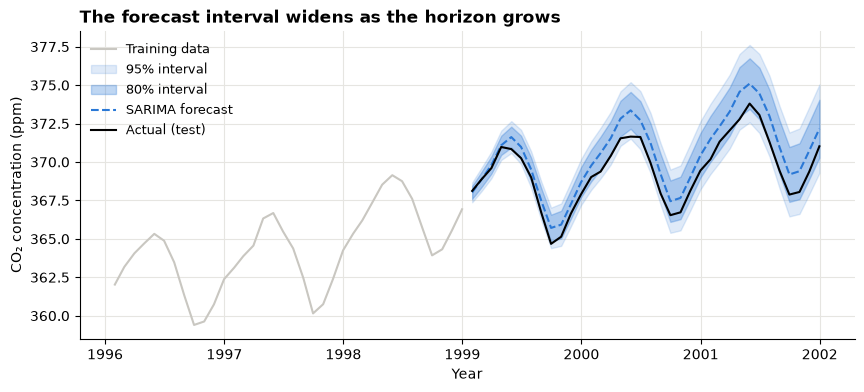

95% interval width  1 months ahead: 1.28 ppm
95% interval width 12 months ahead: 2.99 ppm
95% interval width 36 months ahead: 5.76 ppm
Share of the 36 test months inside the 95% interval: 100%


In [16]:
interval_95 = sarima_forecast.conf_int(alpha=0.05)
interval_80 = sarima_forecast.conf_int(alpha=0.20)

fig, ax = plt.subplots()
ax.plot(train["1996":].index, train["1996":], color=GREY, label="Training data")
ax.fill_between(test.index, interval_95.iloc[:, 0], interval_95.iloc[:, 1], color=BLUE, alpha=0.15, label="95% interval")
ax.fill_between(test.index, interval_80.iloc[:, 0], interval_80.iloc[:, 1], color=BLUE, alpha=0.3, label="80% interval")
ax.plot(test.index, forecasts["SARIMA"], color=BLUE, linestyle="--", label="SARIMA forecast")
ax.plot(test.index, test, color="black", linewidth=1.5, label="Actual (test)")
ax.set_title("The forecast interval widens as the horizon grows")
ax.set_xlabel("Year")
ax.set_ylabel("CO₂ concentration (ppm)")
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.show()

width = interval_95.iloc[:, 1] - interval_95.iloc[:, 0]
for months_ahead in (1, 12, 36):
    print(f"95% interval width {months_ahead:>2} months ahead: {width.iloc[months_ahead - 1]:.2f} ppm")
inside = ((test >= interval_95.iloc[:, 0]) & (test <= interval_95.iloc[:, 1])).mean()
print(f"Share of the 36 test months inside the 95% interval: {inside:.0%}")

Each month ahead adds new, unknown noise on top of the uncertainty already there, so the interval widens with the horizon. Intervals rest on the model's assumptions; a sudden change (a new competitor, a pandemic, a volcano) can push actual values outside them.

**How to say it to a manager:** "We expect about *X* ppm in December 2001; we are 95% confident it will be between *A* and *B*." Give the point forecast **and** the range, and say what the range assumes.

---

## Part 10: Choosing a model and making the decision

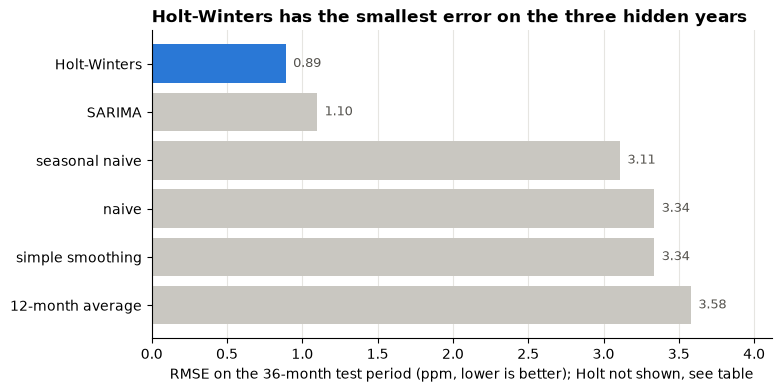

,MAE,RMSE,MAPE %
Holt-Winters,0.810,0.889,0.219
SARIMA,1.007,1.098,0.272
seasonal naive,2.866,3.109,0.774
naive,2.839,3.336,0.766
simple smoothing,2.839,3.336,0.766
12-month average,3.059,3.580,0.825
Holt,22.883,26.696,6.190


In [17]:
ranking = scores.sort_values("RMSE")
best = ranking.index[0]
shown = ranking.drop(index="Holt")   # Holt's error is off the scale; it stays in the table below

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(shown.index[::-1], shown["RMSE"][::-1],
        color=[BLUE if name == best else GREY for name in shown.index[::-1]])
for i, value in enumerate(shown["RMSE"][::-1]):
    ax.text(value + 0.05, i, f"{value:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, shown["RMSE"].max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_title(f"{best} has the smallest error on the three hidden years")
ax.set_xlabel("RMSE on the 36-month test period (ppm, lower is better); Holt not shown, see table")
plt.show()
ranking.round(3)

How to choose, in order:

1. **Beat the baselines.** A model that does not is not worth its complexity.
2. **Prefer the smallest test error** on the measure that matches the decision (RMSE when large misses are costly, MAE otherwise).
3. **Look at the chart**, not only the table: does the forecast follow the trend and the season?
4. **Close results are a tie.** Two models with nearly the same error are equally good on this test; choose the one you can explain, or the one that gives intervals you need.

Once a model is chosen, **refit it on all the data** (training + test) and forecast the real future:

In [18]:
final_model = sm.tsa.statespace.SARIMAX(co2, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
future = final_model.get_forecast(steps=24)
future_table = pd.DataFrame({
    "forecast": future.predicted_mean,
    "95% low": future.conf_int(alpha=0.05).iloc[:, 0],
    "95% high": future.conf_int(alpha=0.05).iloc[:, 1],
})
future_table.index = future_table.index.strftime("%b %Y")
print("Forecast for the next 24 months after the data end (ppm)")
future_table.iloc[[0, 5, 11, 17, 23]].round(1)

Forecast for the next 24 months after the data end (ppm)


,forecast,95% low,95% high
Jan 2002,372.0,371.3,372.6
Jun 2002,374.8,373.7,375.9
Dec 2002,372.5,371.1,374.0
Jun 2003,376.4,374.5,378.2
Dec 2003,374.1,372.0,376.3


### From forecast to decision

A forecast becomes useful when it is tied to a decision and its cost of being wrong:

| Decision | Which number to use | Why |
|---|---|---|
| Order stock that spoils if unsold | Close to the point forecast | Over-ordering wastes stock |
| Order stock where running out loses customers | Near the **upper** end of the interval | A shortage costs more than spare stock |
| Set a budget | Point forecast, with the low end as a risk case | Plan on the likely value, prepare for the bad case |
| Promise a delivery date | The **upper** end of the time forecast | A broken promise costs trust |

> **Remember**
>
> A forecast assumes the future behaves like the past. Re-check it as new data arrive, and say clearly when something has changed that the history does not contain.

> **Check your understanding**
>
> LeafLine Tea forecasts 12,000 drinks next month (95% interval 10,500 to 13,800). Tapioca pearls keep for two weeks, and running out on a busy day loses customers to a rival. Which number would you use to plan pearl orders, and what extra information would change your answer?

---

## Summary

| Idea | One-line takeaway |
|---|---|
| Components | Trend + seasonality + noise; additive when the swing stays the same size |
| Moving average | Centred to describe, trailing to forecast; a trailing average lags a trend |
| Train/test | Hide the most recent period; never shuffle a time series |
| Error | MAE (typical miss), RMSE (punishes big misses), MAPE (per cent; unsafe near zero) |
| Baselines | Naive, seasonal naive, average: a model must beat them |
| Exponential smoothing | Weights shrink into the past; Holt adds trend, Holt-Winters adds season |
| ARIMA | AR (past values) + I (differencing for stationarity) + MA (past errors); ADF p > 0.05 means difference |
| Intervals | Give a range with the forecast; it widens with the horizon |
| Decision | Refit on all data; pick the number (point or interval end) that matches the cost of being wrong |

## Quick reference

| You want to… | Code |
|---|---|
| Weekly to monthly averages | `series.resample("ME").mean()` |
| Decompose | `seasonal_decompose(series, model="additive", period=12)` |
| Moving average | `series.rolling(12).mean()` (trailing), `rolling(12, center=True)` (centred) |
| Time-ordered split | `train, test = series.iloc[:-36], series.iloc[-36:]` |
| Holt-Winters | `ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit().forecast(36)` |
| ADF test | `adfuller(series.dropna())[1]` is the p-value |
| SARIMA | `sm.tsa.statespace.SARIMAX(train, order=(p, d, q), seasonal_order=(P, D, Q, 12)).fit(disp=False)` |
| Forecast and interval | `result.get_forecast(36)`, then `.predicted_mean` and `.conf_int(alpha=0.05)` |
| Errors | `mean_absolute_error`, `mean_squared_error` from `sklearn.metrics`, or the function in Part 6 |

---

## Closing quiz

Answer in your own words, alone, in about two minutes per question.

1. Name the components of a time series and give a business example of each.
2. Why does a trailing 12-month average forecast fall behind a rising series?
3. Why must the test period come after the training period?
4. Actual values 100, 110, 90; forecasts 105, 100, 90. Compute the MAE and the RMSE by hand. Which is larger, and why?
5. What does α control in exponential smoothing? What happens when α is close to 1?
6. An ADF test on monthly revenue gives p = 0.63. What do you conclude, and what do you do before fitting ARIMA?
7. Why does a forecast interval get wider for later months?
8. A model's MAPE on CO₂ is 0.3%. Is that enough to call it excellent? What else would you compare the error with?

---

## This afternoon

**Labs:** [Applied Lab 3: Text mining application](D3_lab_lab3_text_mining.md) and [Applied Lab 4: Forecasting](D3_lab_lab4_forecasting.md) (graded, 3% each). In Lab 4 you test stationarity, split the CO₂ series into training and test sets, fit a seasonal ARIMA model and judge its accuracy with RMSE and MAE.